In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#Get sklearn! https://scikit-learn.org/stable/
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeClassifier, LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [5]:
df = pd.read_csv("/Users/danisanchez/Downloads/LA_AQS_2023.csv")

In [6]:
print(df.columns.tolist())

['State Code', 'County Code', 'Site Number', 'Parameter Code', 'POC', 'Latitude', 'Longitude', 'Datum', 'Parameter Name', 'Duration Description', 'Pollutant Standard', 'Date (Local)', 'Year', 'Day In Year (Local)', 'Units of Measure', 'Exceptional Data Type', 'Nonreg Observation Count', 'Observation Count', 'Observation Percent', 'Nonreg Arithmetic Mean', 'Arithmetic Mean', 'Nonreg First Maximum Value', 'First Maximum Value', 'First Maximum Hour', 'AQI', 'Daily Criteria Indicator', 'Tribe Name', 'State Name', 'County Name', 'City Name', 'Local Site Name', 'Address', 'MSA or CBSA Name', 'Data Source']


In [7]:
print("Available pollutants:", df['Parameter Name'].unique())

Available pollutants: <StringArray>
[   'Ambient Min Temperature',     'Nitrogen dioxide (NO2)',
          'Relative Humidity',        'Outdoor Temperature',
   'Oxides of nitrogen (NOx)',    'Wind Direction - Scalar',
   'Sample Min Baro Pressure', 'Wind Direction - Resultant',
   'Sample Max Baro Pressure',        'Elapsed Sample Time',
 ...
             'Iron (TSP) STP',        'Strontium (TSP) STP',
               'Acetaldehyde',               'Formaldehyde',
        'Methyl ethyl ketone',       'Molybdenum (TSP) STP',
        'Beryllium (TSP) STP',            'Propionaldehyde',
              'Butyraldehyde',              'Hexanaldehyde']
Length: 164, dtype: str


In [8]:
target_pollutants = ['Ozone', 'Nitrogen dioxide (NO2)', 'PM2.5 - Local Conditions']
df_filtered = df[df['Parameter Name'].isin(target_pollutants)]

In [9]:
df_pivoted = df_filtered.pivot_table(
    index=['Date (Local)', 'Site Number'], 
    columns='Parameter Name', 
    values='Arithmetic Mean'
).dropna()

df_pivoted.columns = ['NO2', 'O3', 'PM25']
df_pivoted = df_pivoted.reset_index()

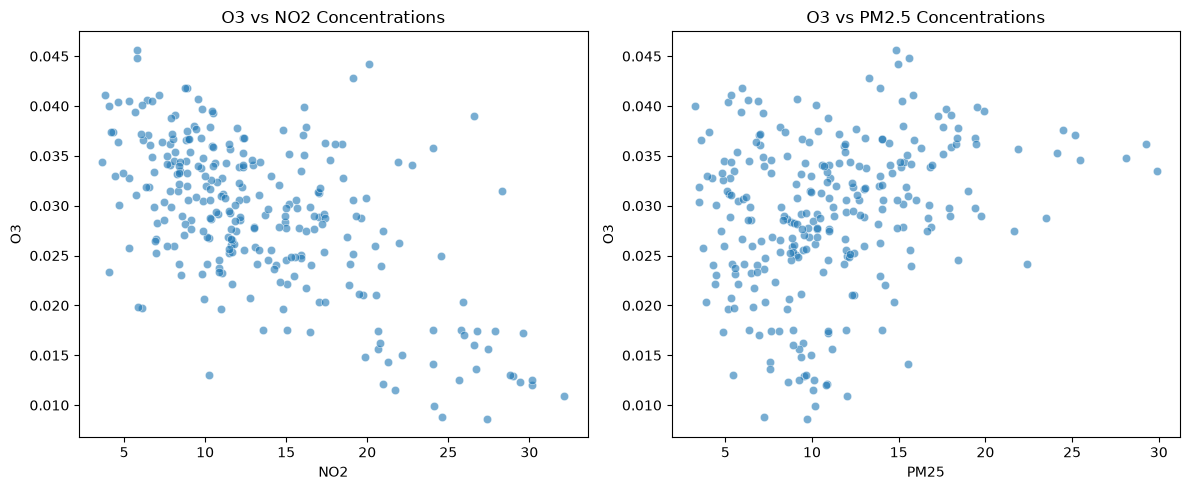

In [10]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_pivoted, x='NO2', y='O3', alpha=0.6)
plt.title('O3 vs NO2 Concentrations')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_pivoted, x='PM25', y='O3', alpha=0.6)
plt.title('O3 vs PM2.5 Concentrations')

plt.tight_layout()
plt.show()

In [16]:
df_pivoted['Date (Local)'] = pd.to_datetime(df_pivoted['Date (Local)'])
df_pivoted['Month'] = df_pivoted['Date (Local)'].dt.month

def get_season(month):
    # Using tuples (6, 7, 8) for Summer and (12, 1, 2) for Winter
    if month in (6, 7, 8):
        return 'summer'
    elif month in (12, 1, 2):
        return 'winter'
    return None

df_pivoted['Season'] = df_pivoted['Month'].apply(get_season)

In [17]:
print(df['Parameter Name'].unique())

<StringArray>
[   'Ambient Min Temperature',     'Nitrogen dioxide (NO2)',
          'Relative Humidity',        'Outdoor Temperature',
   'Oxides of nitrogen (NOx)',    'Wind Direction - Scalar',
   'Sample Min Baro Pressure', 'Wind Direction - Resultant',
   'Sample Max Baro Pressure',        'Elapsed Sample Time',
 ...
             'Iron (TSP) STP',        'Strontium (TSP) STP',
               'Acetaldehyde',               'Formaldehyde',
        'Methyl ethyl ketone',       'Molybdenum (TSP) STP',
        'Beryllium (TSP) STP',            'Propionaldehyde',
              'Butyraldehyde',              'Hexanaldehyde']
Length: 164, dtype: str


In [18]:
all_pollutants = df['Parameter Name'].unique()

no2_name = [p for p in all_pollutants if 'NO2' in p or 'Nitrogen dioxide' in p][0]
o3_name = [p for p in all_pollutants if 'Ozone' in p or 'O3' in p][0]
pm25_name = [p for p in all_pollutants if 'PM2.5' in p or 'PM25' in p][0]

print(f"Detected names:\n- NO2: {no2_name}\n- O3: {o3_name}\n- PM2.5: {pm25_name}")


Detected names:
- NO2: Nitrogen dioxide (NO2)
- O3: Ozone
- PM2.5: PM2.5 - Local Conditions


In [19]:
df_filtered = df[df['Parameter Name'].isin((no2_name, o3_name, pm25_name))]

In [21]:
df_pivoted = df_filtered.pivot_table(
    index=['Date (Local)', 'Site Number'], 
    columns='Parameter Name', 
    values='Arithmetic Mean'
).dropna()

df_pivoted = df_pivoted.rename(columns={no2_name: 'NO2', o3_name: 'O3', pm25_name: 'PM25'}).reset_index()
print(f"pivoted data shape: {df_pivoted.shape}")

pivoted data shape: (273, 5)


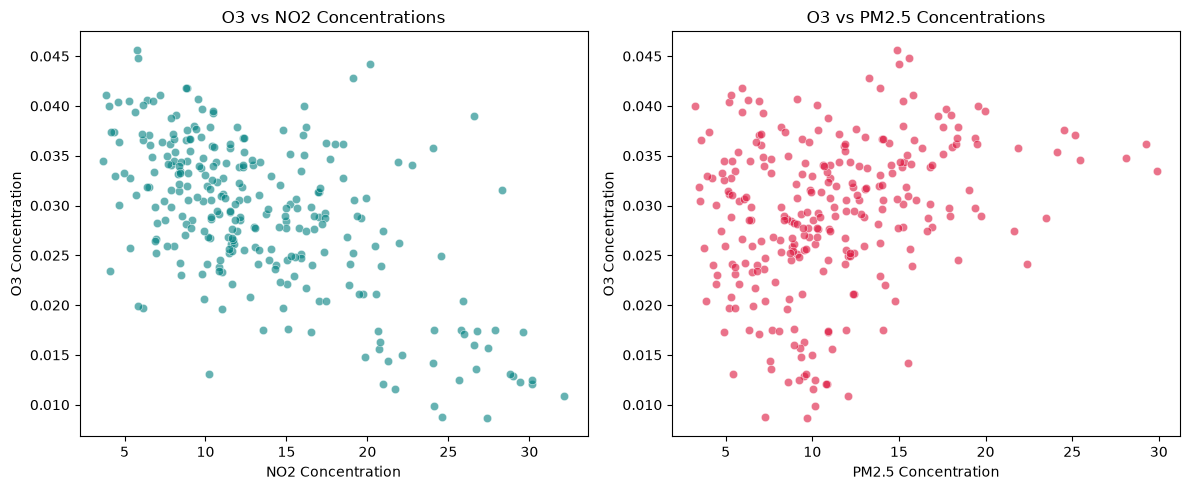

In [22]:
import seaborn as sns

plt.figure(figsize=(12, 5))

# Plot 1: O3 vs NO2
plt.subplot(1, 2, 1)
sns.scatterplot(data=df_pivoted, x='NO2', y='O3', alpha=0.6, color='teal')
plt.title('O3 vs NO2 Concentrations')
plt.xlabel('NO2 Concentration')
plt.ylabel('O3 Concentration')

# Plot 2: O3 vs PM2.5
plt.subplot(1, 2, 2)
sns.scatterplot(data=df_pivoted, x='PM25', y='O3', alpha=0.6, color='crimson')
plt.title('O3 vs PM2.5 Concentrations')
plt.xlabel('PM2.5 Concentration')
plt.ylabel('O3 Concentration')

plt.tight_layout()
plt.show()


In [23]:
df_pivoted['Date (Local)'] = pd.to_datetime(df_pivoted['Date (Local)'])
df_pivoted['Month'] = df_pivoted['Date (Local)'].dt.month

def get_season(month):
    if month in (6, 7, 8):
        return 'summer'
    elif month in (12, 1, 2):
        return 'winter'
    return None

df_pivoted['Season'] = df_pivoted['Month'].apply(get_season)
df_ml = df_pivoted.dropna(subset=['Season']).copy()
df_ml['Target'] = df_ml['Season'].map({'summer': 1, 'winter': 0})

In [24]:
X = df_ml[['O3', 'NO2', 'PM25']]
y = df_ml['Target']

# 3. Create splits (60% Train, 20% Val, 20% Test)
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [27]:
alphas = (0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0)
train_errors = []
val_errors = []

for a in alphas:
    ridge = RidgeClassifier(alpha=a)
    ridge.fit(X_train_scaled, y_train)
    
    # Error = 1 - Accuracy
    train_errors.append(1 - accuracy_score(y_train, ridge.predict(X_train_scaled)))
    val_errors.append(1 - accuracy_score(y_val, ridge.predict(X_val_scaled)))

best_alpha_train = alphas[np.argmin(train_errors)]
best_alpha_val = alphas[np.argmin(val_errors)]

# Final evaluation using optimal validation alpha
final_ridge = RidgeClassifier(alpha=best_alpha_val)
final_ridge.fit(X_train_scaled, y_train)
ridge_test_error = 1 - accuracy_score(y_test, final_ridge.predict(X_test_scaled))

In [28]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)
log_reg_test_error = 1 - accuracy_score(y_test, log_reg.predict(X_test_scaled))

In [30]:
print("HOMEWORK ANSWERS")
print(f"Q3. Optimal Ridge Penalty (Training Data): alpha = {best_alpha_train}")
print(f"Q4. Optimal Ridge Penalty (Validation Data): alpha = {best_alpha_val}")
print(f"Q5. Final Ridge Model Honest Error (Test Set): {ridge_test_error:.4f}")
print(f"Q7. Logistic Regression Error (Test Set): {log_reg_test_error:.4f}")

HOMEWORK ANSWERS
Q3. Optimal Ridge Penalty (Training Data): alpha = 0.001
Q4. Optimal Ridge Penalty (Validation Data): alpha = 100.0
Q5. Final Ridge Model Honest Error (Test Set): 0.0323
Q7. Logistic Regression Error (Test Set): 0.0323
